# Real-graph check: Enron

Does skipping hubs help GOAT on a real network, and only GOAT?

**Graphs**
- **Parent graph:** the Enron employees, with an edge where two people emailed in at least 6 of weeks 101–160. This is September's "sub" parent: 174 people, mean degree 11.9, highest degree 59.
- **Pairs:** A and B each keep every parent edge with the same probability, independently of each other, and B's vertices are shuffled. There are two noise levels, 20 pairs each:
  - edges kept with probability 0.75, as in September (little noise);
  - edges kept with probability 0.60 (more noise).

**Rules:** top degree, hub-free top degree (top degree without its first 10 picks) and random.

**Algorithms:** GOAT, with FAQ and percolation for contrast.

**Outcome: accuracy**, the share of non-seeds matched correctly. Some people lose all their edges in A or B and cannot be matched, so 90% success is often out of reach.

**Predictions** (written before the run)
- **60% kept:** GOAT should do better with hub-free top degree than with top degree at small budgets. FAQ and percolation should not gain, and percolation may lose, since hubs help it.
- **75% kept:** all rules should be close. In a 3-pair calibration, GOAT was already near its best accuracy with 2 seeds.

**Run time.** About 10 minutes.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
if str(EXPERIMENT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR.parent))

from selection_rule_comparison.archive import real_graph_check as RG

RUN_EXPERIMENTS = True   # False: only analyse saved results
COLORS = {'top_degree': '#222222', 'hub_free_top_degree': '#FF7F0E', 'random': '#9E9E9E'}

## Run

Progress prints below, one line per pair. From a terminal: `python -m selection_rule_comparison.real_graph_check`.

In [2]:
if RUN_EXPERIMENTS:
    RG.run_all(jobs=3)

01:23:06 Enron parent graph: 174 people, mean degree 11.9. 40 pairs to run, 3 at a time.
01:24:27 [1/40] keep 0.60 pair 1: 72 evaluations in 67 s
01:24:33 [2/40] keep 0.60 pair 2: 72 evaluations in 72 s
01:24:50 [3/40] keep 0.60 pair 0: 72 evaluations in 90 s
01:26:05 [4/40] keep 0.60 pair 4: 72 evaluations in 91 s
01:26:07 [5/40] keep 0.60 pair 3: 72 evaluations in 100 s
01:26:39 [6/40] keep 0.60 pair 5: 72 evaluations in 108 s
01:27:08 [7/40] keep 0.60 pair 6: 72 evaluations in 63 s
01:27:14 [8/40] keep 0.60 pair 7: 72 evaluations in 67 s
01:27:57 [9/40] keep 0.60 pair 8: 72 evaluations in 79 s
01:28:21 [10/40] keep 0.60 pair 9: 72 evaluations in 73 s
01:28:24 [11/40] keep 0.60 pair 10: 72 evaluations in 70 s
01:29:21 [12/40] keep 0.60 pair 11: 72 evaluations in 84 s
01:29:24 [13/40] keep 0.60 pair 13: 72 evaluations in 60 s
01:29:28 [14/40] keep 0.60 pair 12: 72 evaluations in 67 s
01:30:48 [15/40] keep 0.60 pair 15: 72 evaluations in 83 s
01:31:15 [16/40] keep 0.60 pair 16: 72 eval

## 1. The graphs

Each row averages over that noise level's 20 pairs.
- **Unmatchable:** people with no edges in A or in B.
- **Edges kept:** the share of A's edges that are also in B.

In [3]:
runs = RG.load_runs()
graphs = runs.groupby(['keep', 'pair_index'])[['n', 'mean_degree', 'max_degree', 'unmatchable', 'edges_kept']].first()
graphs = graphs.groupby('keep').mean()
graphs.index = [f'{k:.0%} kept' for k in graphs.index]
graphs.columns = ['people', 'mean degree', 'max degree', 'unmatchable', 'edges kept']
display(graphs.round(2))

,people,mean degree,max degree,unmatchable,edges kept
60% kept,174.0,7.08,36.85,6.25,0.61
75% kept,174.0,8.88,45.90,2.30,0.75


## 2. Accuracy against the number of seeds

Each row is an algorithm, and each column a noise level. Each point is the mean accuracy over the 20 pairs.

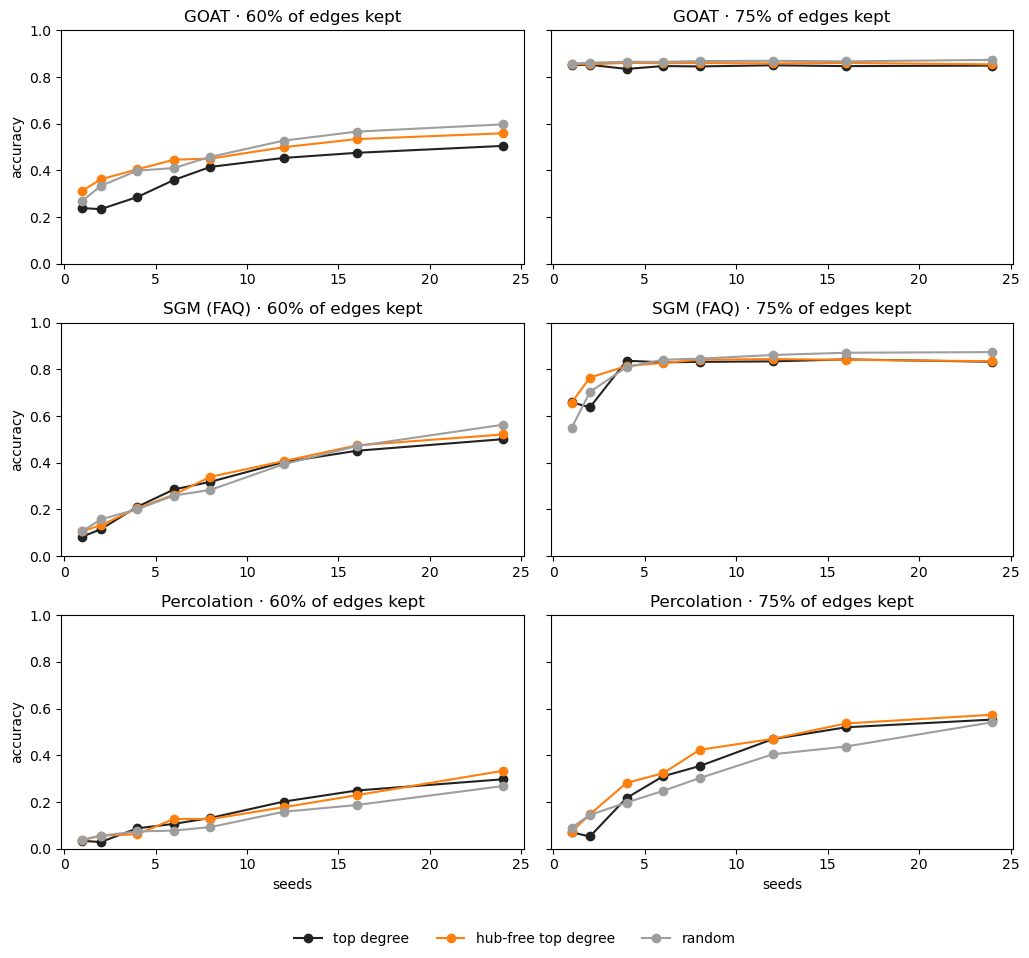

In [4]:
keeps = sorted(runs['keep'].unique())
algorithms = [a for a in RG.ALGORITHMS if a in set(runs['algorithm'])]
fig, axes = plt.subplots(len(algorithms), len(keeps), figsize=(5.2 * len(keeps), 3.2 * len(algorithms)),
                         sharey='row', squeeze=False)
for row, algorithm in enumerate(algorithms):
    for column, keep in enumerate(keeps):
        ax = axes[row, column]
        data = runs[(runs['algorithm'] == algorithm) & np.isclose(runs['keep'], keep)]
        for rule in RG.RULES:
            curve = data[data['rule'] == rule].groupby('budget')['accuracy'].mean()
            ax.plot(curve.index, curve.values, marker='o', color=COLORS[rule], label=RG.LABELS[rule])
        ax.set_title(f'{RG.ALGORITHM_LABELS[algorithm]} · {keep:.0%} of edges kept')
        ax.set_ylim(0, 1)
    axes[row, 0].set_ylabel('accuracy')
for ax in axes[-1]:
    ax.set_xlabel('seeds')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 3. Hub-free top degree against top degree

The comparison is pair by pair at 2, 4 and 8 seeds.
- **Better / same / worse:** pairs where hub-free top degree's accuracy is higher, within 0.005, or lower.
- **p:** a sign test of better against worse.
- **Mean change:** accuracy of hub-free minus top degree, with a 95% bootstrap interval.

In [5]:
rows = []
for algorithm in algorithms:
    for keep in keeps:
        for budget in (2, 4, 8):
            rows.append({'algorithm': RG.ALGORITHM_LABELS[algorithm], 'edges kept': f'{keep:.0%}', 'seeds': budget,
                         **RG.compare(runs, algorithm, keep, budget, 'hub_free_top_degree', 'top_degree')})
display(pd.DataFrame(rows).set_index(['algorithm', 'edges kept', 'seeds']).round(3))

better  same  worse      p  \
algorithm   edges kept seeds                               
GOAT        60%        2          15     0      5  0.041   
                       4          15     0      5  0.041   
                       8          15     0      5  0.041   
            75%        2           9     1     10  1.000   
                       4          12     0      8  0.503   
                       8          14     1      5  0.064   
SGM (FAQ)   60%        2          12     2      6  0.238   
                       4          10     1      9  1.000   
                       8          11     0      9  0.824   
            75%        2          13     0      7  0.263   
                       4           7     4      9  0.804   
                       8          13     1      6  0.167   
Percolation 60%        2          16     0      4  0.012   
                       4           5     1     14  0.064   
                       8           9     0     11  0.824   
            75%        2          15     0      5  0.041   
                       4          15     0      5  0.041   
                       8          16     0      4  0.012   

                                          mean change  
algorithm   edges kept seeds                           
GOAT        60%        2      +0.128 [+0.060, +0.198]  
                       4      +0.119 [+0.049, +0.190]  
                       8      +0.036 [-0.011, +0.081]  
            75%        2      +0.002 [-0.014, +0.018]  
                       4      +0.026 [-0.001, +0.067]  
                       8      +0.014 [-0.003, +0.033]  
SGM (FAQ)   60%        2      +0.017 [-0.029, +0.065]  
                       4      -0.006 [-0.049, +0.035]  
                       8      +0.021 [-0.024, +0.073]  
            75%        2      +0.128 [+0.000, +0.266]  
                       4      -0.023 [-0.049, -0.001]  
                       8      +0.009 [-0.007, +0.026]  
Percolation 60%        2      +0.027 [+0.010, +0.042]  
                       4      -0.025 [-0.043, -0.007]  
                       8      -0.005 [-0.033, +0.024]  
            75%        2      +0.095 [+0.031, +0.173]  
                       4      +0.065 [+0.006, +0.124]  
                       8      +0.070 [+0.008, +0.127]